# Exercise 1: Derivatives of Core Activation Functions

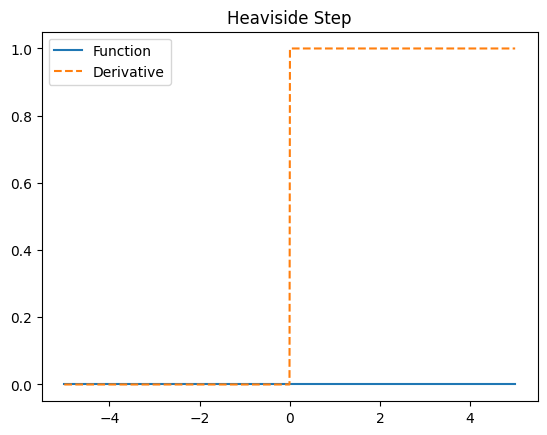

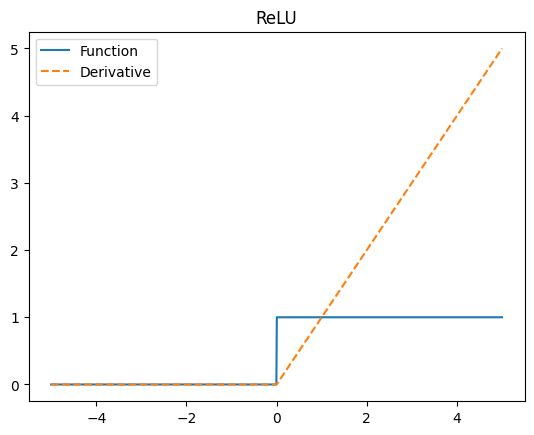

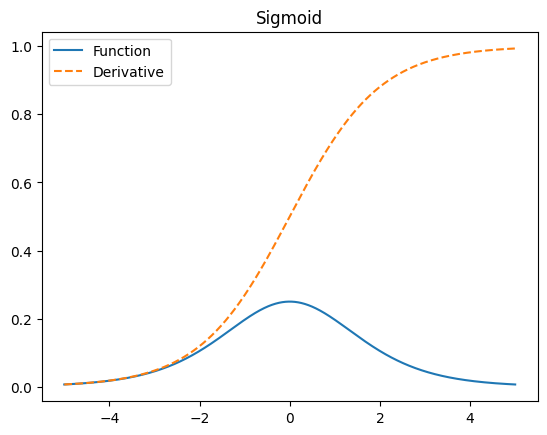

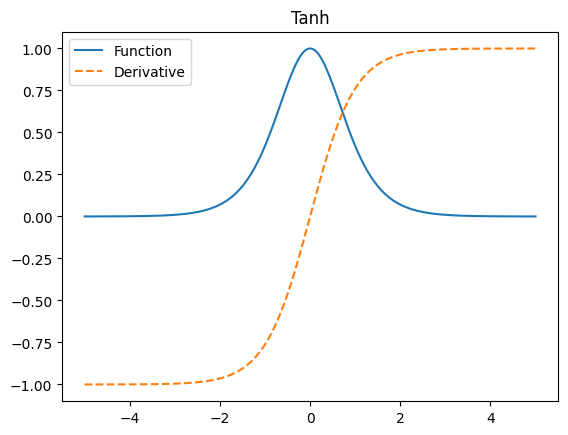

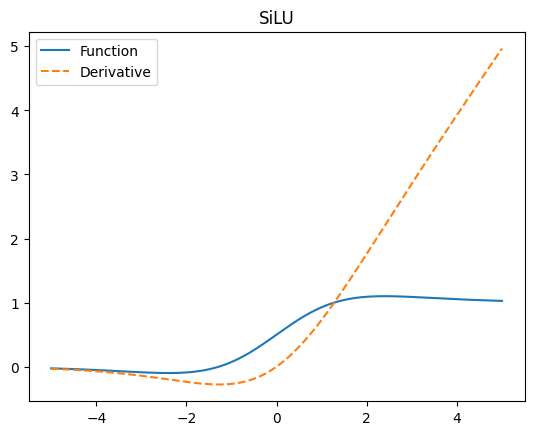

In [2]:
import activationsWDerivatives as actD
import numpy as np
import matplotlib.pyplot as plt

a = -10
x = np.linspace(-5,5,1000)
#
def DerPlot(x,F1,F2,ttl):
  plt.plot(x,F2)
  plt.plot(x,F1,linestyle='--')
  plt.legend(["Function","Derivative"])
  plt.title(ttl)
  plt.show()

DerPlot(x,actD.heaviside_step(x),actD.heaviside_step_derivative(x),"Heaviside Step")

DerPlot(x,actD.relu(x),actD.relu_derivative(x),"ReLU")

DerPlot(x,actD.sigmoid(x),actD.sigmoid_derivative(x),"Sigmoid")

DerPlot(x,actD.tanh(x),actD.tanh_derivative(x),"Tanh")

DerPlot(x,actD.silu(x),actD.silu_derivative(x),"SiLU")

# Exercise 2: Implementing MLP and its Solution Strategy

In [5]:
# 1 Import some data - XOR problem
X_train = np.array([[0,0],[1,0],[0,1],[1,1]])
y_train = np.array([[0],[1],[1],[0]])
X_test = X_train
y_test = y_train



In [6]:
import lossFunctions as lossF

n_input = 2 # Number of input nodes / features
n_hidden_nodes = 3 # Number of hidden nodes
n_outputs = 1 # Number of outputs
lr = 0.1 # Learning rate
max_iter = 10000 # Maximum iterations

### Begin Training
## Initialise
W1 = np.random.randn(n_input, n_hidden_nodes) * 0.1
b1 = np.zeros((1, n_hidden_nodes))
W2 = np.random.randn(n_hidden_nodes, n_outputs) * 0.1
b2 = np.zeros((1, n_outputs))
print(W1)
print(b1)
print(W2)
print(b2)
## Training Loop
for i in range(max_iter):
    ## Forward Pass
    # Inner Layer
    U1 = np.dot(X_train,W1) + b1
    A1 = actD.relu(U1)
    # Output layer
    U2 = np.dot(A1,W2) + b2
    output = actD.sigmoid(U2)
    ## Calculate loss
    loss = lossF.MSE_loss(y_train, output)
    ## Do backward propagation
    m = X_train.shape[0]
    # Output layer error
    dU2 = (output - y_train) * actD.sigmoid_derivative(output)
    dW2 = np.dot(A1.T,dU2) / m
    db2 = np.sum(dU2, axis=0, keepdims=True) / m
    # Hidden layer error
    dA1 = np.dot(dU2,W2.T)
    dU1 = dA1 * actD.relu_derivative(U1)
    dW1 = np.dot(X_train.T,dU1) / m
    db1 = np.sum(dU1, axis=0, keepdims=True) / m
    # Update weights
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1

    if i % 1000 == 0:
        print(f"Epoch {i:4d} | Loss: {loss:.6f}")

### Make Prediction
U1 = np.dot(X_test, W1) + b1
A1 = actD.relu(U1)
U2 = np.dot(A1, W2) + b2
A2 = actD.sigmoid(U2)
y_pred = A2
print(y_pred)


[[ 0.03485974 -0.13506035  0.15784781]
 [ 0.12567791 -0.11862046  0.0163293 ]]
[[0. 0. 0.]]
[[-0.00207736]
 [ 0.14663027]
 [ 0.05419531]]
[[0.]]
Epoch    0 | Loss: 0.250002
Epoch 1000 | Loss: 0.249970
Epoch 2000 | Loss: 0.247685
Epoch 3000 | Loss: 0.208882
Epoch 4000 | Loss: 0.148949
Epoch 5000 | Loss: 0.049269
Epoch 6000 | Loss: 0.012962
Epoch 7000 | Loss: 0.004700
Epoch 8000 | Loss: 0.002217
Epoch 9000 | Loss: 0.001238
[[0.05064068]
 [0.98485062]
 [0.98484635]
 [0.00829806]]


# Exercise 3: Derivatives of Additional Activation Functions

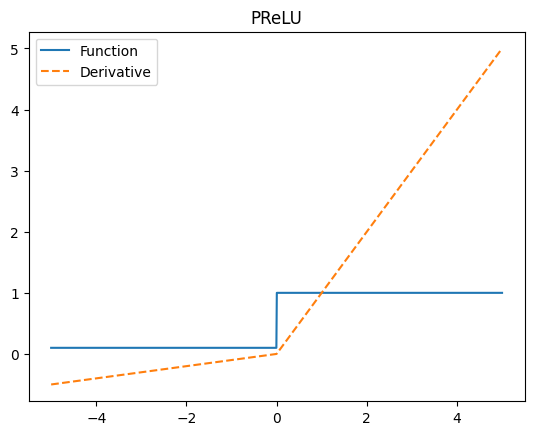

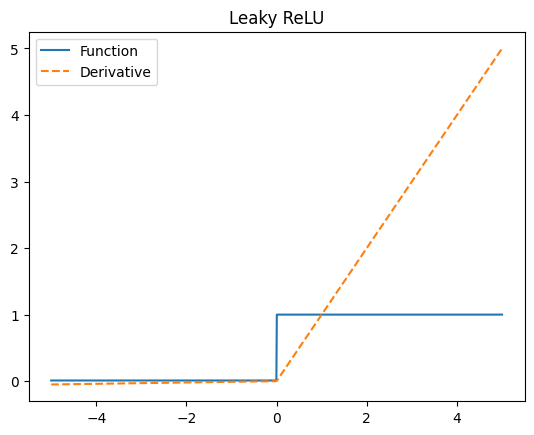

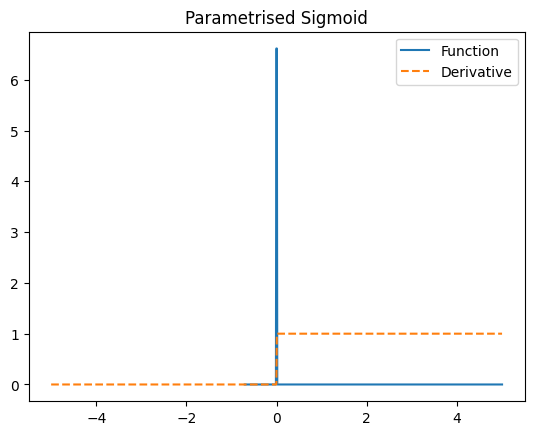

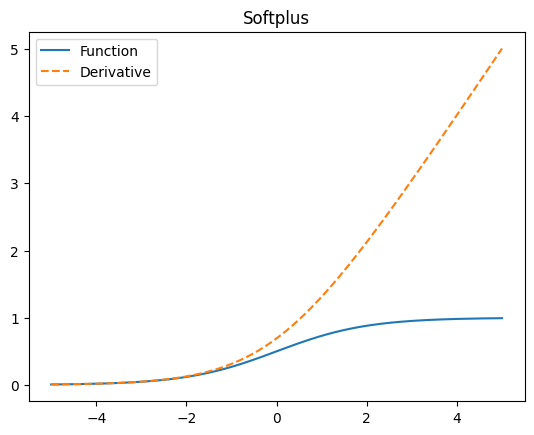

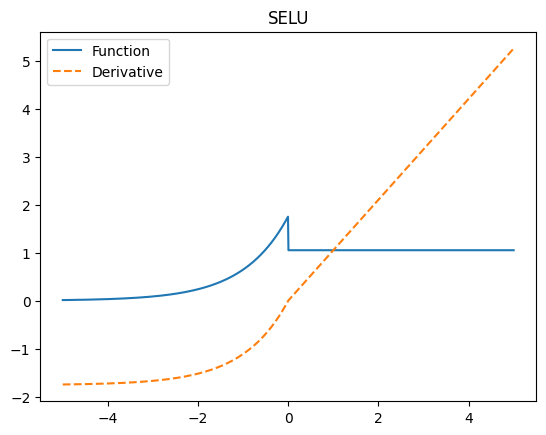

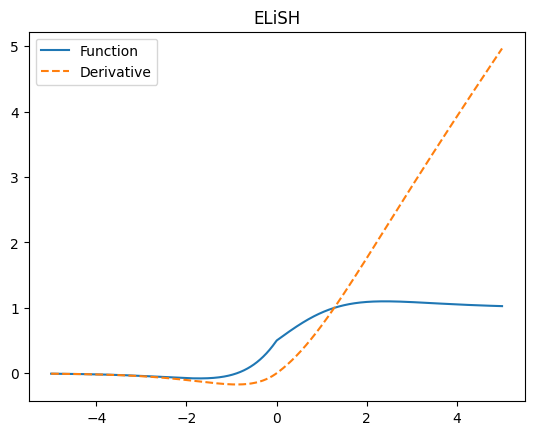

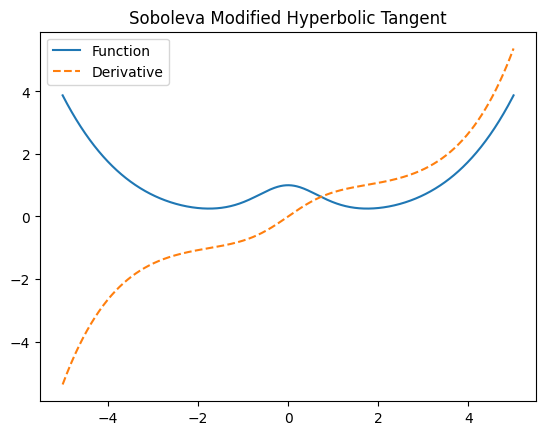

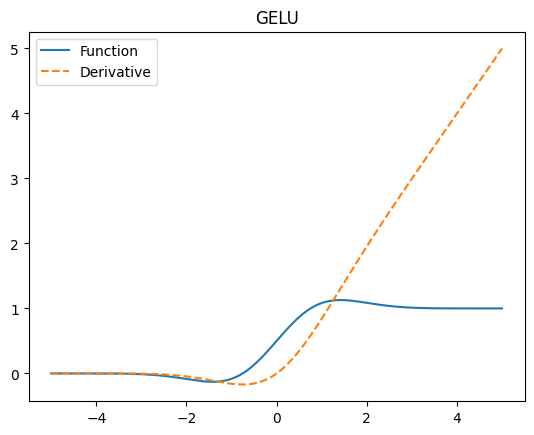

In [4]:
import activationsWDerivatives as actD
import numpy as np
import matplotlib.pyplot as plt

a = -10
x = np.linspace(-5,5,1000)
#
alpha = 0.1
DerPlot(x,actD.prelu(x,alpha),actD.prelu_derivative(x,alpha),"PReLU")
#
DerPlot(x,actD.leaky_relu(x),actD.leaky_relu_derivative(x),"Leaky ReLU")
#
alpha = 0.001
DerPlot(x,actD.parametrised_sigmoid(x,alpha),actD.parametrised_sigmoid_derivative(x,alpha),"Parametrised Sigmoid")
#
#DerPlot(x,actD.softsign(x),actD.softsign_derivative(x),"Softsign")
#
DerPlot(x,actD.softplus(x),actD.softplus_derivative(x),"Softplus")
#
DerPlot(x,actD.selu(x),actD.selu_derivative(x),"SELU")
#
DerPlot(x,actD.elish(x),actD.elish_derivative(x),"ELiSH")
#
DerPlot(x,actD.soboleva_tanh(x),actD.soboleva_tanh_derivative(x),"Soboleva Modified Hyperbolic Tangent")
#
DerPlot(x,actD.gelu(x),actD.gelu_derivative(x),"GELU")


# Exercise 4: Create a Model Class

Training MLP for Exercise 4...
Epoch     0 | Loss: 0.274873
Epoch  2000 | Loss: 0.000017
Epoch  4000 | Loss: 0.000003
Epoch  6000 | Loss: 0.000001
Epoch  8000 | Loss: 0.000000
Epoch  9999 | Loss: 0.000000

Target Labels:
 [[0]
 [1]
 [1]
 [0]]

Predicted Outputs:
 [[7.000e-04]
 [9.996e-01]
 [9.995e-01]
 [3.000e-04]]

Binary Predictions (Threshold = 0.5):
 [[0]
 [1]
 [1]
 [0]]


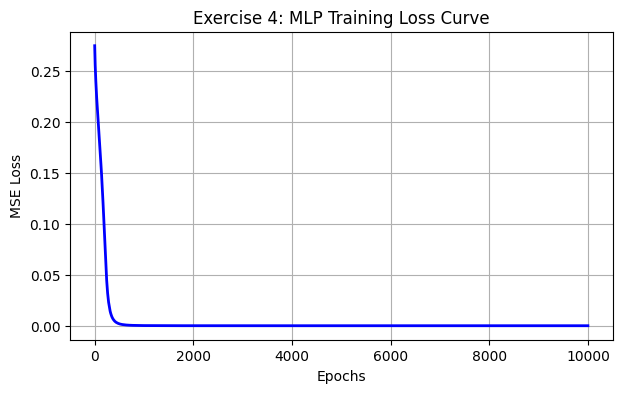

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import lossFunctions as lossF
import activationsWDerivatives as actD

# ==========================================
# Exercise 4 Solution: Flexible MLP Class
# ==========================================

class MultilayerPerceptron:
    def __init__(self, n_input, n_hidden, n_output, lr=0.1):
        """
        Initializes weights and biases for a 2-layer MLP.
        """
        self.lr = lr

        # He/Xavier initialization for weights
        self.W1 = np.random.randn(n_input, n_hidden) * np.sqrt(2.0 / n_input)
        self.b1 = np.zeros((1, n_hidden))

        self.W2 = np.random.randn(n_hidden, n_output) * np.sqrt(2.0 / n_hidden)
        self.b2 = np.zeros((1, n_output))

    def forward(self, X):
        """
        Computes forward pass through hidden and output layers.
        """
        self.U1 = np.dot(X, self.W1) + self.b1
        self.A1 = actD.relu(self.U1)  # Hidden Layer Activation (ReLU)

        self.U2 = np.dot(self.A1, self.W2) + self.b2
        self.A2 = actD.sigmoid(self.U2)  # Output Layer Activation (Sigmoid)

        return self.A2

    def backward(self, X, Y, Y_pred):
        """
        Computes gradients via Backpropagation and updates model parameters.
        """
        m = X.shape[0]

        # 1. Output Layer Gradient
        # Derivative of MSE loss wrt U2 using Sigmoid output:
        # dL/dA2 = (A2 - Y), dA2/dU2 = sigmoid_derivative(A2)
        dU2 = (Y_pred - Y) * actD.sigmoid_derivative(Y_pred)
        dW2 = np.dot(self.A1.T, dU2) / m
        db2 = np.sum(dU2, axis=0, keepdims=True) / m

        # 2. Hidden Layer Gradient
        dA1 = np.dot(dU2, self.W2.T)
        dU1 = dA1 * actD.relu_derivative(self.U1)
        dW1 = np.dot(X.T, dU1) / m
        db1 = np.sum(dU1, axis=0, keepdims=True) / m

        # 3. Update Weights and Biases
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def fit(self, X, Y, epochs=10000, print_every=1000):
        """
        Trains the MLP using gradient descent.
        """
        loss_history = []
        for epoch in range(epochs):
            # Forward Pass
            Y_pred = self.forward(X)

            # Compute Loss
            loss = lossF.MSE_loss(Y, Y_pred)
            loss_history.append(loss)

            # Backward Pass & Parameter Update
            self.backward(X, Y, Y_pred)

            if epoch % print_every == 0 or epoch == epochs - 1:
                print(f"Epoch {epoch:5d} | Loss: {loss:.6f}")

        return loss_history


# ==========================================
# Execution / Verification
# ==========================================
if __name__ == "__main__":
    # Dataset: Non-linear XOR Problem
    X = np.array([[0, 0],
                  [1, 0],
                  [0, 1],
                  [1, 1]])

    Y = np.array([[0],
                  [1],
                  [1],
                  [0]])

    # Instantiate MLP: 2 Inputs -> 4 Hidden Neurons -> 1 Output Neuron
    mlp = MultilayerPerceptron(n_input=2, n_hidden=4, n_output=1, lr=0.5)

    print("Training MLP for Exercise 4...")
    history = mlp.fit(X, Y, epochs=10000, print_every=2000)

    # Predictions
    predictions = mlp.forward(X)
    print("\nTarget Labels:\n", Y)
    print("\nPredicted Outputs:\n", np.round(predictions, 4))
    print("\nBinary Predictions (Threshold = 0.5):\n", (predictions >= 0.5).astype(int))

    # Plot Loss Curve
    plt.figure(figsize=(7, 4))
    plt.plot(history, color='blue', linewidth=2)
    plt.title("Exercise 4: MLP Training Loss Curve")
    plt.xlabel("Epochs")
    plt.ylabel("MSE Loss")
    plt.grid(True)
    plt.show()